# Receipt photo metrics: reproducible analysis

This notebook recomputes item-label coverage, current paired total scores, the separate line-amount retrieval and 16-pair row-scoring add-on, and recorded runtimes. It reads existing CSV/JSON artifacts only; it runs no model inference and does not edit source labels. The labels are assistant-audited/unverified except for three explicitly user-confirmed product fields on two receipts.

In [1]:
from pathlib import Path
import csv, json, io, runpy
from contextlib import redirect_stdout
root = Path('.')  # run from this folder
with redirect_stdout(io.StringIO()):
    runpy.run_path(str(root/'analyze_receipt_photo_metrics.py'), run_name='__main__')
print('Recomputed CSV/JSON and chart outputs in', root)

Recomputed CSV/JSON and chart outputs in <PROJECT_ROOT>\2026-09-30\task\analysis_handoff_2026-10-07


## Cohort and item-label coverage

In [2]:
summary=json.loads((root/'analysis_evidence.json').read_text(encoding='utf-8'))
for k,v in summary.items():
 if k!='input_files': print(k,':',v)
print('\nLegacy label rows per receipt:')
with (root/'receipt_item_label_counts.csv').open(encoding='utf-8',newline='') as f: rows=list(csv.DictReader(f))
for dataset in ('legacy_reference_v3_1','receipy_references_v2'):
 a=[x for x in rows if x['dataset']==dataset]
 print(dataset, 'receipts=',len(a),'annotated rows=',sum(int(x['annotated_rows']) for x in a),'product rows=',sum(int(x['product_rows']) for x in a if x['product_rows']))
print('\nVersioned row-count reconciliation:')
with (root/'row_count_reconciliation.csv').open(encoding='utf-8',newline='') as f: rows=list(csv.DictReader(f))
for r in rows: print(r['count_basis'],r['entries'],r['unit'])

main_current_photo_cohort : {'paired_receipt_ids': 50, 'selected_views': 100, 'views_each_condition': 50, 'known_total_refs': 99, 'unknown_total_refs': 1, 'extra_unscored_views': 22, 'completed_routes': ['Tesseract+rules', 'LayoutLMv3', 'TrOCR+LayoutLMv3', 'Donut', 'GLM-OCR', 'Qwen3.5-2B'], 'Qwen3.5-4B': 'placeholder not run; excluded'}
legacy_reference_inventory : {'receipts': 34, 'line_item_rows': 120, 'line_item_row_count_distribution': {'1': 17, '2': 3, '3': 4, '4': 1, '6': 3, '8': 2, '9': 1, '10': 1, '11': 1, '17': 1}, 'human_verified_receipts': 0, 'partially_user_reviewed_records': 5}
receipy_independent_audit_inventory : {'high_confidence_pairs': 16, 'selected_views': 32, 'complete_visible_inventory_ledgers': 15, 'fragment_excluded_from_row_prf1': 1, 'eligible_row_candidates_before_field_unknown_filter': 58, 'eligible_name_targets': 56, 'eligible_quantity_targets': 39, 'eligible_line_total_targets': 45, 'eligible_unit_price_targets': 22, 'all_human_verified': False}
user_confirm

## Total match by model and condition

In [3]:
with (root/'current_total_accuracy_by_model_condition.csv').open(encoding='utf-8',newline='') as f: rows=list(csv.DictReader(f))
for r in rows:
 print(f"{r['route']:22s} {r['condition']:10s} {r['candidate_exact_n']}/{r['known_reference_n']} ({100*float(r['candidate_accuracy']):.1f}%), Wilson 95% [{100*float(r['wilson95_low']):.1f}, {100*float(r['wilson95_high']):.1f}]")

Tesseract+rules        clear      14/50 (28.0%), Wilson 95% [17.5, 41.7]
Tesseract+rules        scrunched  6/49 (12.2%), Wilson 95% [5.7, 24.2]
LayoutLMv3             clear      6/50 (12.0%), Wilson 95% [5.6, 23.8]
LayoutLMv3             scrunched  0/49 (0.0%), Wilson 95% [0.0, 7.3]
TrOCR+LayoutLMv3       clear      14/50 (28.0%), Wilson 95% [17.5, 41.7]
TrOCR+LayoutLMv3       scrunched  4/49 (8.2%), Wilson 95% [3.2, 19.2]
Donut                  clear      15/50 (30.0%), Wilson 95% [19.1, 43.8]
Donut                  scrunched  15/49 (30.6%), Wilson 95% [19.5, 44.5]
GLM-OCR                clear      43/50 (86.0%), Wilson 95% [73.8, 93.0]
GLM-OCR                scrunched  45/49 (91.8%), Wilson 95% [80.8, 96.8]
Qwen3.5-2B             clear      41/50 (82.0%), Wilson 95% [69.2, 90.2]
Qwen3.5-2B             scrunched  41/49 (83.7%), Wilson 95% [71.0, 91.5]


## Paired clear-to-scrunched changes

In [4]:
with (root/'current_paired_clear_scrunched_total_changes.csv').open(encoding='utf-8',newline='') as f: rows=list(csv.DictReader(f))
for r in rows:
 print(f"{r['route']:22s} pairs={r['fully_labeled_pairs_n']} clear-only={r['clear_only_correct_n']} scrunched-only={r['scrunched_only_correct_n']} delta={float(r['scrunched_minus_clear_paired_accuracy_pp']):+.2f} pp, paired-bootstrap 95% [{float(r['paired_receipt_bootstrap95_low_pp']):+.2f}, {float(r['paired_receipt_bootstrap95_high_pp']):+.2f}]")

Tesseract+rules        pairs=49 clear-only=12 scrunched-only=4 delta=-16.33 pp, paired-bootstrap 95% [-30.61, +0.00]
LayoutLMv3             pairs=49 clear-only=6 scrunched-only=0 delta=-12.24 pp, paired-bootstrap 95% [-22.45, -4.08]
TrOCR+LayoutLMv3       pairs=49 clear-only=13 scrunched-only=3 delta=-20.41 pp, paired-bootstrap 95% [-34.69, -6.12]
Donut                  pairs=49 clear-only=9 scrunched-only=9 delta=+0.00 pp, paired-bootstrap 95% [-16.33, +16.33]
GLM-OCR                pairs=49 clear-only=2 scrunched-only=4 delta=+4.08 pp, paired-bootstrap 95% [-6.12, +14.29]
Qwen3.5-2B             pairs=49 clear-only=3 scrunched-only=4 delta=+2.04 pp, paired-bootstrap 95% [-8.16, +12.24]


## Line amounts, item rows, runtimes and plot

Legacy EXIF-only amount multiset retrieval:
Tesseract+rules clear 14/141 = 9.9% paired delta pp -3.55
Tesseract+rules scrunched 9/141 = 6.4% paired delta pp -3.55
LayoutLMv3 clear 19/141 = 13.5% paired delta pp -4.26
LayoutLMv3 scrunched 13/141 = 9.2% paired delta pp -4.26
TrOCR+LayoutLMv3 clear 15/141 = 10.6% paired delta pp -3.55
TrOCR+LayoutLMv3 scrunched 10/141 = 7.1% paired delta pp -3.55
Donut clear 5/141 = 3.5% paired delta pp +2.84
Donut scrunched 9/141 = 6.4% paired delta pp +2.84

Receipy exact row F1:
Tesseract+rules clear F1=0.000, TP=0 FP=9 FN=58, n=15
Tesseract+rules scrunched F1=0.000, TP=0 FP=4 FN=58, n=15
LayoutLMv3 clear F1=0.000, TP=0 FP=535 FN=58, n=15
LayoutLMv3 scrunched F1=0.000, TP=0 FP=411 FN=58, n=15
TrOCR+LayoutLMv3 clear F1=0.000, TP=0 FP=264 FN=58, n=15
TrOCR+LayoutLMv3 scrunched F1=0.000, TP=0 FP=213 FN=58, n=15
Donut clear F1=0.000, TP=0 FP=14 FN=58, n=15
Donut scrunched F1=0.000, TP=0 FP=32 FN=58, n=15

Runtime:
classic four combined sequential pipeline 

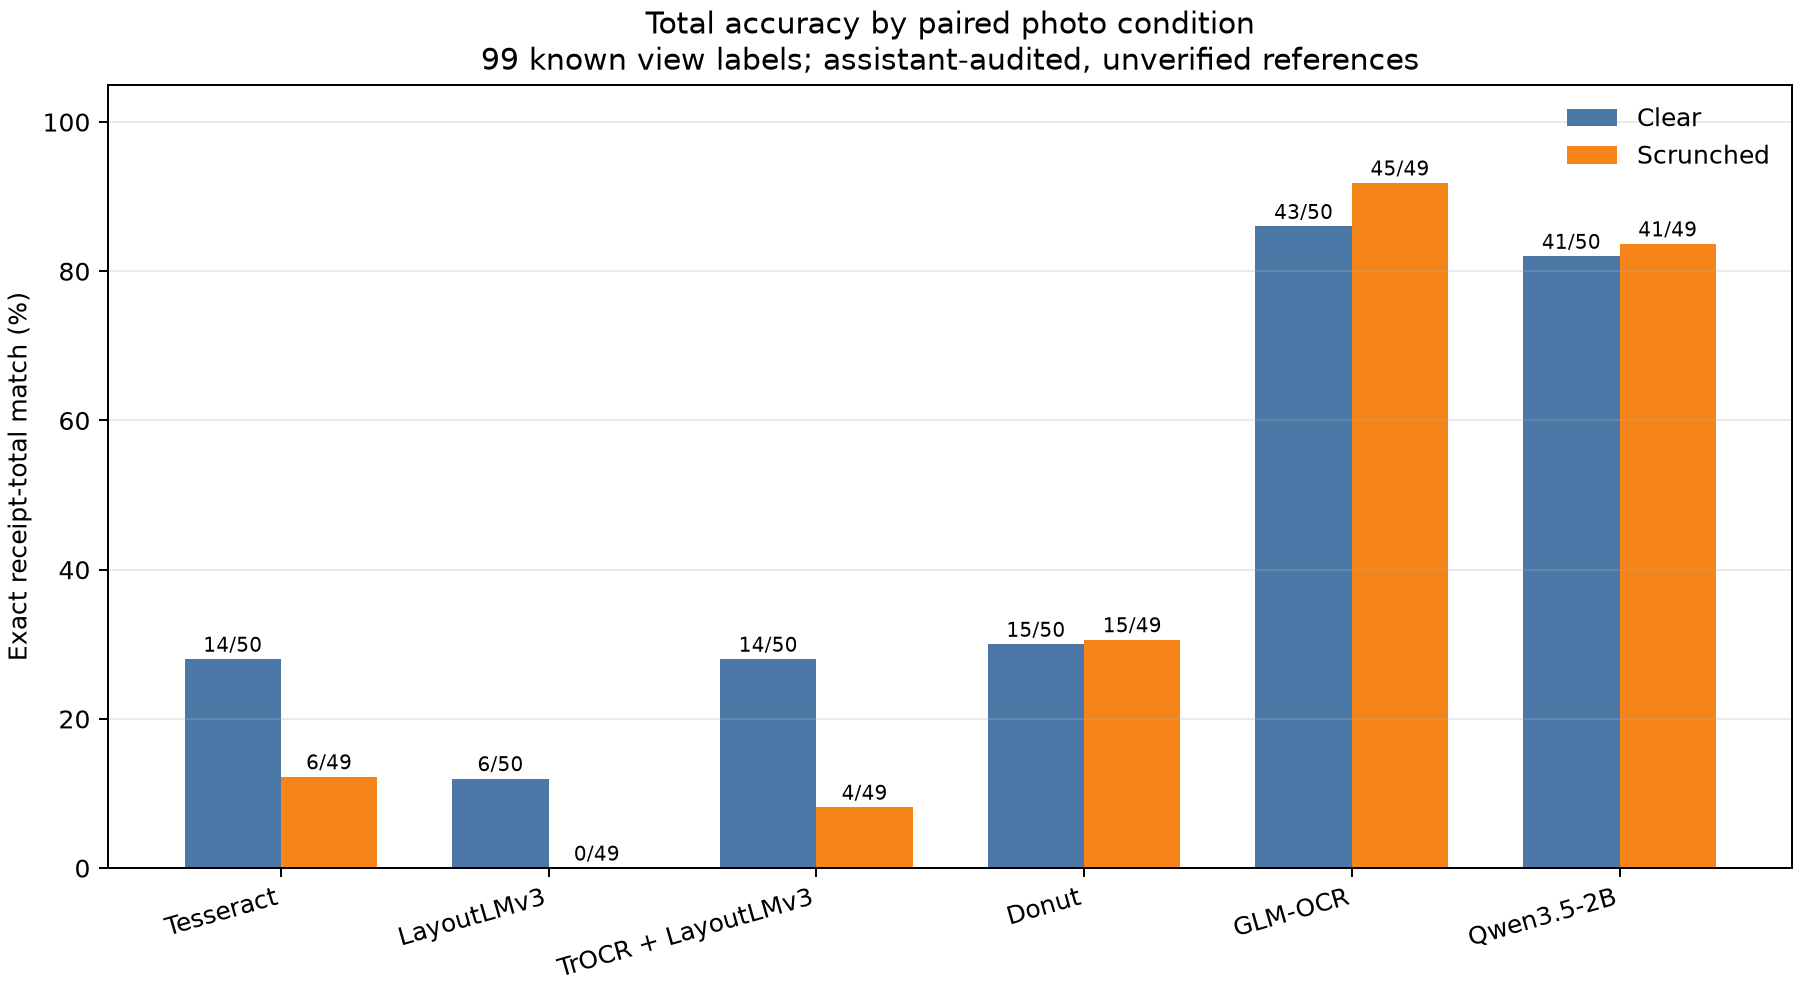


Per-image timing rows: 100 (classic combined, GLM route, Qwen total/generation; no classic per-model split)


In [5]:
print('Legacy EXIF-only amount multiset retrieval:')
with (root/'legacy_line_amount_retrieval_exif_only.csv').open(encoding='utf-8',newline='') as f: rows=list(csv.DictReader(f))
for r in rows:
 print(r['model'],r['condition'],f"{r['exact_amount_values_retrieved']}/{r['known_amount_targets_n']} = {100*float(r['amount_value_recall']):.1f}%",'paired delta pp',f"{float(r['scrunched_minus_clear_recall_pp']):+.2f}")
print('\nReceipy exact row F1:')
with (root/'receipy_row_accuracy_by_model_condition.csv').open(encoding='utf-8',newline='') as f: rows=list(csv.DictReader(f))
for r in rows:print(r['route'],r['condition'],f"F1={float(r['f1']):.3f}, TP={r['tp']} FP={r['fp']} FN={r['fn']}, n={r['complete_visible_inventories']}")
print('\nRuntime:')
with (root/'runtime_by_route_summary.csv').open(encoding='utf-8',newline='') as f: rows=list(csv.DictReader(f))
for r in rows:print(r['route'],f"n={r['primary_views_n']}, mean={float(r['mean_seconds_per_view']):.2f}s, median={float(r['median_seconds_per_view']):.2f}s, p95={float(r['p95_seconds_per_view']):.2f}s")
from IPython.display import display, Image
display(Image(filename=str(root/'total_accuracy_clear_vs_scrunched.png')))
with (root/'per_image_timing.csv').open(encoding='utf-8',newline='') as f: timing=list(csv.DictReader(f))
print('\nPer-image timing rows:',len(timing),'(classic combined, GLM route, Qwen total/generation; no classic per-model split)')